# MSBD 566 – Small Task and Explainable AI

**Name:** David Reyes  
**Course:** MSBD 566  
**Date:** November 6, 2026

I compared feature importance using our BRFSS 2015 diabetes data. I then added a noise check and a SHAP explanation for Lecture 11.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")
X = df.drop(columns="Diabetes_012")
y = (df["Diabetes_012"] > 0).astype(int)  # 1 = prediabetes or diabetes
print("Data shape:", df.shape)
print("Identical response rows:", int(df.duplicated().sum()))

Data shape: (253680, 22)
Identical response rows: 23899


## 1. Split And Train

I held out validation rows so the model would not train on the same rows used to measure permutation importance.

In [2]:
X_work, X_test, y_work, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_work, y_work, test_size=0.20, stratify=y_work, random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=20,
    class_weight="balanced", random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
print("Validation AUC:", round(roc_auc_score(y_valid, rf.predict_proba(X_valid)[:, 1]), 4))

Validation AUC: 0.8245


## 2. Compare Feature Importance

Built-in importance measures how useful each feature was when splitting trees. Permutation importance measures how much the held-out AUC drops when a feature is shuffled.

In [3]:
built_in = pd.Series(rf.feature_importances_, index=X.columns)

# Use 5,000 held-out rows to make permutation faster
X_perm, _, y_perm, _ = train_test_split(
    X_valid, y_valid, train_size=5000, stratify=y_valid, random_state=42
)
permutation = permutation_importance(
    rf, X_perm, y_perm, scoring="roc_auc",
    n_repeats=10, random_state=42, n_jobs=1
)

results = pd.DataFrame({
    "Built-in": built_in,
    "Permutation AUC drop": permutation.importances_mean
})
results["Built-in rank"] = results["Built-in"].rank(ascending=False, method="min").astype(int)
results["Permutation rank"] = results["Permutation AUC drop"].rank(ascending=False, method="min").astype(int)
results["Rank difference"] = (results["Built-in rank"] - results["Permutation rank"]).abs()

display(results.sort_values("Rank difference", ascending=False).round(4))

,Built-in,Permutation AUC drop,Built-in rank,Permutation rank,Rank difference
PhysHlth,0.0360,-0.0005,8,21,13
CholCheck,0.0071,0.0018,16,7,9
HvyAlcoholConsump,0.0069,0.0013,17,9,8
Smoker,0.0102,-0.0001,14,20,6
Income,0.0458,0.0004,6,12,6
NoDocbcCost,0.0024,0.0002,20,14,6
MentHlth,0.0186,0.0001,11,16,5
Sex,0.0132,0.0015,12,8,4
HeartDiseaseorAttack,0.0218,0.0018,9,6,3
DiffWalk,0.0426,0.0010,7,10,3


## 3. One Disagreement

**PhysHlth** measures the number of days of poor physical health. The built-in method ranked it much higher than permutation importance. It may overlap with other health features, so shuffling it has little impact because the forest can still use related information. Built-in importance can also favor features with more possible split values.

In [4]:
print(results.loc["PhysHlth"].round(4))
print("\nCorrelations with PhysHlth:")
print(X_train[["PhysHlth", "GenHlth", "DiffWalk"]].corr(method="spearman")["PhysHlth"].round(3))

Built-in                 0.0360
Permutation AUC drop    -0.0005
Built-in rank            8.0000
Permutation rank        21.0000
Rank difference         13.0000
Name: PhysHlth, dtype: float64

Correlations with PhysHlth:
PhysHlth    1.000
GenHlth     0.451
DiffWalk    0.416
Name: PhysHlth, dtype: float64


## Original Task Summary

I trained a random forest on our BRFSS 2015 diabetes data. One feature where the two methods disagreed was **PhysHlth** (days of poor physical health). Built-in importance ranked it **8th of 21**, but permutation importance gave it a mean AUC drop of **-0.0005**, which is essentially zero. This may happen because other features, such as **GenHlth** and **DiffWalk**, already provide similar health information. So the forest used PhysHlth while building trees, but shuffling it barely changed the model’s AUC on held-out data.

**Repeated rows:** The data has 23,899 identical rows but no person ID, so I could not group the split by person.

**GitHub link:** https://github.com/reyesd23036/MSBD566-Small-Task-DR

**Data:** https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset

## 4. Check A Noise Column

I added random numbers with no intended connection to the outcome and trained a separate copy of the same forest. I checked its built-in importance and how much validation AUC changed when I shuffled only the noise column. A little built-in credit does not mean the noise is useful.

In [5]:
import numpy as np
from sklearn.base import clone

rng = np.random.default_rng(42)
X_train_noise = X_train.copy()
X_valid_noise = X_valid.copy()
X_train_noise['RandomNoise'] = rng.normal(size=len(X_train))
X_valid_noise['RandomNoise'] = rng.normal(size=len(X_valid))

rf_noise = clone(rf).fit(X_train_noise, y_train)
X_noise_check = X_valid_noise.loc[X_perm.index].copy()
noise_auc = roc_auc_score(y_perm, rf_noise.predict_proba(X_noise_check)[:, 1])
noise_drops = []
for repeat in range(10):
    shuffled = X_noise_check.copy()
    shuffled['RandomNoise'] = rng.permutation(shuffled['RandomNoise'])
    noise_drops.append(noise_auc - roc_auc_score(
        y_perm, rf_noise.predict_proba(shuffled)[:, 1]))

noise_result = pd.Series({
    'Built-in importance': rf_noise.feature_importances_[-1],
    'Mean permutation AUC drop': np.mean(noise_drops)
})
print('Noise-model validation AUC (all validation rows):', round(
    roc_auc_score(y_valid, rf_noise.predict_proba(X_valid_noise)[:, 1]), 4))
display(noise_result.round(4))

Noise-model validation AUC (all validation rows): 0.8241


Built-in importance          0.0554
Mean permutation AUC drop   -0.0006
dtype: float64

## 5. Explain One Prediction With SHAP

I explained the first validation response using the original forest. Red bars raise the model score and blue bars lower it relative to the SHAP starting value. These explain this model's output, not causes or medical advice. The starting value is a model reference, not the survey event rate. Because the forest uses class balancing, its score is not a calibrated personal disease probability.

Note: you may need to restart the kernel to use updated packages.
Model score: 0.0306
SHAP starting value: 0.5


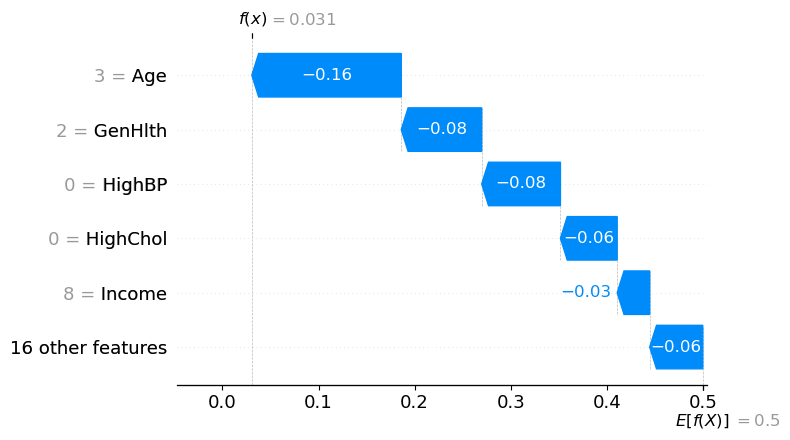

For this survey response, the model gave a score of 3% for recorded prediabetes or diabetes, with age group pushing it down and reported general health pushing it down; this describes the model, not a diagnosis.


In [8]:
%pip -q install shap==0.49.1
import shap
import matplotlib.pyplot as plt

person = X_valid.iloc[[0]]
explainer = shap.TreeExplainer(rf)
explanation = explainer(person)
positive = explanation[0, :, 1]  # Class 1 = prediabetes or diabetes
person_score = rf.predict_proba(person)[0, 1]
print('Model score:', round(person_score, 4))
print('SHAP starting value:', round(float(positive.base_values), 4))
shap.plots.waterfall(positive, max_display=6, show=False)
plt.tight_layout()
plt.show()

top_two = pd.Series(positive.values, index=X.columns).abs().nlargest(2).index
labels = {'GenHlth': 'reported general health', 'BMI': 'BMI', 'Age': 'age group',
          'HighBP': 'reported high blood pressure', 'HighChol': 'reported high cholesterol',
          'Income': 'income group', 'DiffWalk': 'reported walking difficulty'}
parts = []
for feature in top_two:
    direction = 'up' if positive.values[X.columns.get_loc(feature)] > 0 else 'down'
    parts.append(f"{labels.get(feature, feature)} pushing it {direction}")
print(f"For this survey response, the model gave a score of {person_score:.0%} for "
      f"recorded prediabetes or diabetes, with {' and '.join(parts)}; "
      "this describes the model, not a diagnosis.")

## 6. Reading Response

**Reading:** Cynthia Rudin (2019), first three pages: https://arxiv.org/abs/1811.10154

**Main point:** We should consider models people can understand directly, especially for important decisions. A more complicated model is not always more accurate, and an explanation can miss parts of how it works.

**My response:** I agree that our diabetes project should compare the forest or boosting model against a simpler baseline such as logistic regression. If the two perform about the same, the simpler model is easier to audit and explain, which matters for a screening tool. SHAP shows how features contribute to this model’s prediction under its explanation assumptions, but it cannot prove that the prediction is correct or safe for screening.

## Lecture 11 Summary

The noise column received **5.54% of built-in importance**, but shuffling it changed AUC by about **-0.0006**, essentially zero. This suggests that its training importance did not translate into useful validation information in this run. These measures use different scales. The SHAP plot explains an actual validation response with a model score of about **3%**; age group and general health were the two largest downward contributions. The printed sentence explains this result in plain language.

**Repeated responses:** Matching answers do not establish repeated people. The file has no person ID, so person-grouped splitting cannot be checked.

**Data:** https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset   
**SHAP documentation:** https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html  